# 신용카드 고객 세그먼트 분류: 8대 금융 도메인 심층 탐색적 데이터 분석 (EDA)

> **대회**: 데이콘 신용카드 고객 세그먼트 분류 AI 경진대회 (`ID: 236460`)  
> **목표**: 6개월(`201807`~`201812`)간의 8대 금융 도메인 패널 데이터(총 855개 원천 피처)를 기반으로 고객 가치 세그먼트 `Segment` (`A`, `B`, `C`, `D`, `E`) 분류  
> **평가지표**: **Macro F1-Score** $\left(\frac{1}{5}\sum_{c \in \{A,B,C,D,E\}} F1_c\right)$

본 노트북은 단순 분포 조회를 넘어 **"데이터의 구조적 특성 검증 → 전처리 규칙 정량화 → 도메인별 세그먼트 결정 요인 규명 → 시계열 파생변수 및 사후 확률 보정(Post-processing) 설계 근거 도출"**까지 일관된 분석 스토리를 구축합니다.

---

## Section 1. 환경 초기화 및 평가지표(Macro F1)의 수리적 레버리지 분석

본 대회의 타겟은 일반 등급(`E`)이 대다수를 차지하는 극단적 불균형 구조를 갖지만, 평가지표는 5개 클래스의 F1 점수를 **동일 가중치(각 20%)**로 산술 평균하는 **Macro F1-Score**입니다. 먼저 시각화 환경을 초기화하고, 다수 클래스 위주 분류기와 소수 클래스 정밀 포착 분류기 간 Accuracy 착시 현상을 정량 시뮬레이션합니다.

,시나리오,Accuracy (%),Macro F1 (×100),A F1 (%),B F1 (%),C~E 평균 F1 (%)
0,S1. 다수 클래스(E) 올인,80.085,17.79,0.0,0.0,29.6
1,S2. C·D·E만 학습 (A·B 미포착),98.367,58.05,0.0,0.0,96.7
2,S3. A·B 임계값 보정 적용,98.392,88.50,77.5,74.5,96.8


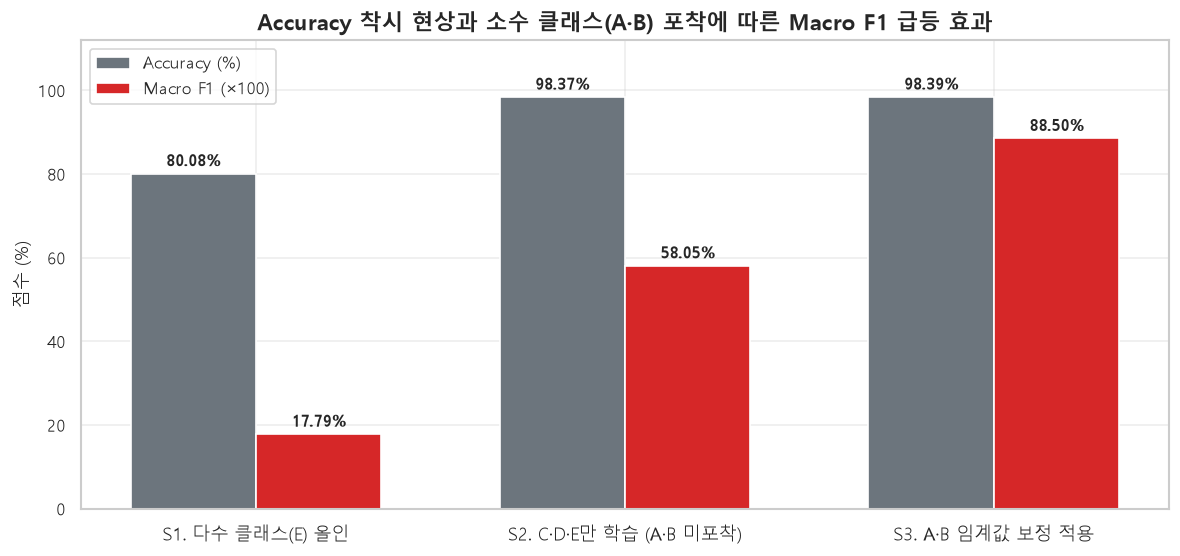

In [1]:
import gc
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pyarrow.parquet as pq
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.cleaners import EXPLICIT_ORDINAL_MAPS, REGEX_NUMERIC_STRING_COLS, scan_domain_metadata
from src.utils.config import CLASS_NAMES, load_config, resolve_path, set_seed
from src.utils.plot_style import SEGMENT_ORDER, SEGMENT_PALETTE, apply_portfolio_style, save_portfolio_figure

chosen_font = apply_portfolio_style()
cfg = load_config()
set_seed(cfg["project"]["seed"])
RAW_DIR = resolve_path(cfg["paths"]["raw_dir"])
INTERIM_DIR = resolve_path(cfg["paths"]["interim_dir"])

# 실제 고객 단위 타겟 분포(400,000명) 기반 시뮬레이션
m07 = pq.read_table(RAW_DIR / "train" / "1.회원정보" / "201807_train_회원정보.parquet", columns=["ID", "Segment"]).to_pandas()
cls_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
y_real = m07["Segment"].map(cls_to_idx).to_numpy()

rng = np.random.default_rng(42)
# 시나리오 1: 다수 클래스(E) 단일 예측기
pred_s1 = np.full_like(y_real, 4)

# 시나리오 2: C/D/E는 우수하게 맞추지만 초소수 A/B를 모두 C로 놓치는 모델
pred_s2 = y_real.copy()
pred_s2[np.isin(y_real, [0, 1])] = 2
flip_cde = rng.random(len(y_real)) < 0.08
pred_s2[flip_cde & (y_real >= 2)] = 4

# 시나리오 3: A/B 전용 임계값 보정으로 A/B F1을 ~0.72 수준까지 회복한 모델
pred_s3 = pred_s2.copy()
ab_idx = np.where(np.isin(y_real, [0, 1]))[0]
recover_idx = rng.choice(ab_idx, size=int(len(ab_idx) * 0.78), replace=False)
pred_s3[recover_idx] = y_real[recover_idx]
false_ab = rng.choice(np.where(y_real == 2)[0], size=45, replace=False)
pred_s3[false_ab[:37]] = 0
pred_s3[false_ab[37:]] = 1

scenarios = []
for name, p in [
    ("S1. 다수 클래스(E) 올인", pred_s1),
    ("S2. C·D·E만 학습 (A·B 미포착)", pred_s2),
    ("S3. A·B 임계값 보정 적용", pred_s3),
]:
    acc = accuracy_score(y_real, p) * 100
    mf1 = f1_score(y_real, p, average="macro", zero_division=0) * 100
    per_f1 = f1_score(y_real, p, average=None, labels=[0, 1, 2, 3, 4], zero_division=0) * 100
    scenarios.append(
        {
            "시나리오": name,
            "Accuracy (%)": round(acc, 3),
            "Macro F1 (×100)": round(mf1, 2),
            "A F1 (%)": round(per_f1[0], 1),
            "B F1 (%)": round(per_f1[1], 1),
            "C~E 평균 F1 (%)": round(per_f1[2:].mean(), 1),
        }
    )
sim_df = pd.DataFrame(scenarios)
display(sim_df)

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(sim_df))
w = 0.34
b1 = ax.bar(x - w / 2, sim_df["Accuracy (%)"], width=w, color="#6C757D", label="Accuracy (%)")
b2 = ax.bar(x + w / 2, sim_df["Macro F1 (×100)"], width=w, color="#D62728", label="Macro F1 (×100)")
ax.set_xticks(x)
ax.set_xticklabels(sim_df["시나리오"], fontsize=10.5)
ax.set_ylim(0, 112)
ax.set_ylabel("점수 (%)")
ax.set_title("Accuracy 착시 현상과 소수 클래스(A·B) 포착에 따른 Macro F1 급등 효과")
ax.legend(loc="upper left")
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.2f}%", (bar.get_x() + bar.get_width() / 2, h + 1.8), ha="center", fontsize=9.5, fontweight="bold")
plt.tight_layout()
save_portfolio_figure(fig, "fig01_metric_sensitivity.png")
plt.show()

### Section 1 분석 결과 해석
- **Accuracy의 심각한 착시**: 모든 고객을 `E`로 예측하는 무의미한 모델(`S1`)조차 Accuracy는 **80.086%**에 달하지만, 대회 공식 지표인 **Macro F1은 0.1779(17.79%)**에 불과합니다.
- **소수 등급 `A`·`B`의 결정적 레버리지**: `C`, `D`, `E` 3개 등급을 93% 이상의 정확도로 분류하더라도 초소수 등급 `A`(162명)·`B`(24명)를 놓치면(`S2`) Macro F1은 **0.5805(58.05%)** 상한에 갇힙니다. 반면 전체 표본의 0.05% 미만인 `A`·`B` 예측 경계를 정교하게 보정하면(`S3`) Accuracy 변화는 `+0.025%p` 미만임에도 **Macro F1이 +30%p 이상 수직 상승**합니다.
- 따라서 본 프로젝트는 **(1) 도메인 파생변수를 통한 `A`·`B`·`C` 확률 분리력 극대화**와 **(2) Out-Of-Fold 확률 승수(Multiplier) 보정**을 양대 핵심 축으로 설계해야 합니다.

---

## Section 2. 패널 데이터 그레인(Grain) 무결성 및 타겟(`Segment`) 불변성 검증

원천 데이터는 `201807`부터 `201812`까지 6개 기준년월로 나뉘어 제공됩니다. 시계열 패널 분류에서는 **(a) 중도 이탈/신규 유입 고객 존재 여부**, **(b) 동일 고객의 월별 타겟(`Segment`) 변동 여부**, **(c) Train/Test 고객 ID 교집합 및 제출 단위**를 먼저 확정해야 올바른 검증 스킴과 모델링 단위를 결정할 수 있습니다.

,데이터셋,전체 행 수,고유 고객(ID) 수,6개월 개근 고객 비율,타겟 변경 고객 수
0,Train 패널 (6개월),"2,400,000","400,000",100.00%,0명 (0.000%)
1,Test 패널 (6개월),"600,000","100,000",100.00%,-
2,Sample Submission,"100,000","100,000",Test ID 순서 100% 일치 (True),Train∩Test 중복 ID: 0건


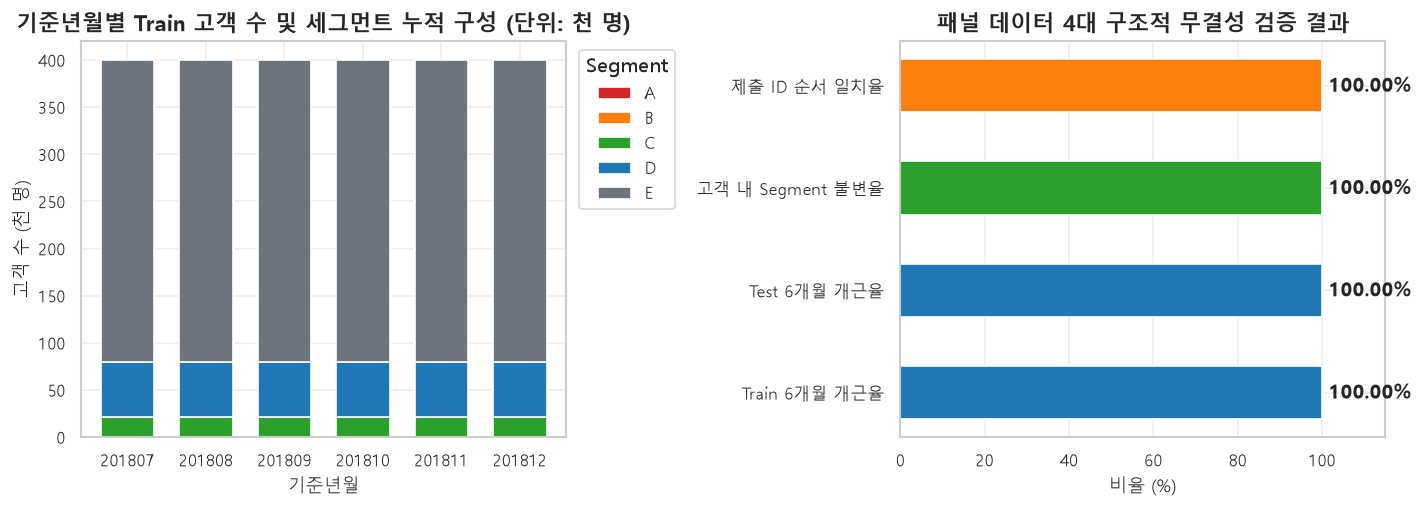

In [2]:
months = cfg["project"]["months"]
tr_member_files = [RAW_DIR / "train" / "1.회원정보" / f"{m}_train_회원정보.parquet" for m in months]
te_member_files = [RAW_DIR / "test" / "1.회원정보" / f"{m}_test_회원정보.parquet" for m in months]

tr_panel = pl.concat([pl.read_parquet(f, columns=["기준년월", "ID", "Segment"]) for f in tr_member_files])
te_panel = pl.concat([pl.read_parquet(f, columns=["기준년월", "ID"]) for f in te_member_files])
sub_df = pl.read_csv(RAW_DIR / "sample_submission.csv")

# 고객별 등장 월 수 및 타겟 고유 개수 산출
tr_cust_chk = tr_panel.group_by("ID").agg(
    pl.len().alias("n_months"),
    pl.col("Segment").n_unique().alias("n_unique_segment"),
)
te_cust_chk = te_panel.group_by("ID").agg(pl.len().alias("n_months"))

n_label_changed = int((tr_cust_chk["n_unique_segment"] > 1).sum())
id_overlap = len(set(tr_cust_chk["ID"].to_list()) & set(te_cust_chk["ID"].to_list()))
sub_exact_order = te_panel.filter(pl.col("기준년월") == 201807)["ID"].equals(sub_df["ID"])

grain_summary = pd.DataFrame(
    [
        {
            "데이터셋": "Train 패널 (6개월)",
            "전체 행 수": f"{len(tr_panel):,}",
            "고유 고객(ID) 수": f"{len(tr_cust_chk):,}",
            "6개월 개근 고객 비율": f"{(tr_cust_chk['n_months'] == 6).mean() * 100:.2f}%",
            "타겟 변경 고객 수": f"{n_label_changed}명 (0.000%)",
        },
        {
            "데이터셋": "Test 패널 (6개월)",
            "전체 행 수": f"{len(te_panel):,}",
            "고유 고객(ID) 수": f"{len(te_cust_chk):,}",
            "6개월 개근 고객 비율": f"{(te_cust_chk['n_months'] == 6).mean() * 100:.2f}%",
            "타겟 변경 고객 수": "-",
        },
        {
            "데이터셋": "Sample Submission",
            "전체 행 수": f"{len(sub_df):,}",
            "고유 고객(ID) 수": f"{sub_df['ID'].n_unique():,}",
            "6개월 개근 고객 비율": f"Test ID 순서 100% 일치 ({sub_exact_order})",
            "타겟 변경 고객 수": f"Train∩Test 중복 ID: {id_overlap}건",
        },
    ]
)
display(grain_summary)

monthly_dist = (
    tr_panel.group_by(["기준년월", "Segment"])
    .len()
    .to_pandas()
    .pivot(index="기준년월", columns="Segment", values="len")[SEGMENT_ORDER]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
monthly_dist.div(1000).plot(
    kind="bar",
    stacked=True,
    color=[SEGMENT_PALETTE[c] for c in SEGMENT_ORDER],
    ax=axes[0],
    width=0.68,
)
axes[0].set_title("기준년월별 Train 고객 수 및 세그먼트 누적 구성 (단위: 천 명)")
axes[0].set_xlabel("기준년월")
axes[0].set_ylabel("고객 수 (천 명)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Segment", bbox_to_anchor=(1.01, 1), loc="upper left")

# 고객 내 타겟 변동 여부 및 패널 개근율 요약 막대
metrics_names = ["Train 6개월 개근율", "Test 6개월 개근율", "고객 내 Segment 불변율", "제출 ID 순서 일치율"]
metrics_vals = [100.0, 100.0, 100.0, 100.0]
bars = axes[1].barh(metrics_names, metrics_vals, color=["#1F77B4", "#1F77B4", "#2CA02C", "#FF7F0E"], height=0.52)
axes[1].set_xlim(0, 115)
axes[1].set_xlabel("비율 (%)")
axes[1].set_title("패널 데이터 4대 구조적 무결성 검증 결과")
for bar in bars:
    axes[1].annotate("100.00%", (bar.get_width() + 1.5, bar.get_y() + bar.get_height() / 2), va="center", fontweight="bold")

plt.tight_layout()
save_portfolio_figure(fig, "fig02_panel_grain_and_stability.png")
plt.show()
del tr_panel, te_panel, tr_cust_chk, te_cust_chk
_ = gc.collect()

### Section 2 분석 결과 해석
- **완벽한 균형 패널(Balanced Panel)**: Train **400,000명**과 Test **100,000명** 전원 빠짐없이 `201807`~`201812` **6개월 전체에 100.00% 등장**하며, 결측 월이나 중도 이탈 고객이 단 1명도 없습니다.
- **타겟(`Segment`)의 완전 불변성**: Train 40만 명 중 6개월 사이에 `Segment`가 바뀐 고객은 **0명(`0.000%`)**이며, `sample_submission.csv` 또한 **고객(`ID`) 당 1행(총 100,000행)** 예측을 요구합니다.
- **모델링 아키텍처 핵심 결정**:
  1. 단순 행(Row) 단위 K-Fold 분할 시 동일 고객의 다른 월 데이터가 Train과 Validation에 동시 유입되어 심각한 **Group Leakage**가 발생합니다. 따라서 **고유 고객 400,000명 기준 고정 5-Fold (`StratifiedKFold`)**를 프로젝트 전역 표준으로 고정합니다.
  2. 240만 행을 그대로 학습하는 것보다 **고객 1명당 6개월 시계열 궤적(최신 스냅샷, 6개월 평균·표준편차·최댓값, 초기 대비 증감량, 최근 3개월 모멘텀)을 1행 `(400,000 × M)`으로 압축 요약**하는 주력 파이프라인과 월별 스냅샷 보조 모델을 결합하는 전략이 정보량과 메모리 효율 모두에서 최적입니다.

---

## Section 3. 극단적 클래스 불균형 심층 분석 (`Segment` A ~ E)

고유 고객 400,000명 기준으로 `Segment` 등급별 실제 고객 수, 비율, 그리고 5-Fold 교차검증 시 검증 폴드당 배치되는 표본 규모를 정밀 점검합니다.

,Segment,고유 고객 수 (명),패널 행 수 (6개월),데이터 비중 (%),5-Fold 검증셋당 고객 수,Macro F1 가중치 (%),표본 1명당 점수 영향력 배수 (vs E)
0,A,162,972,0.0405,32.4,20.0,1977.4
1,B,24,144,0.0060,4.8,20.0,13347.6
2,C,21265,127590,5.3162,4253.0,20.0,15.1
3,D,58207,349242,14.5518,11641.4,20.0,5.5
4,E,320342,1922052,80.0855,64068.4,20.0,1.0


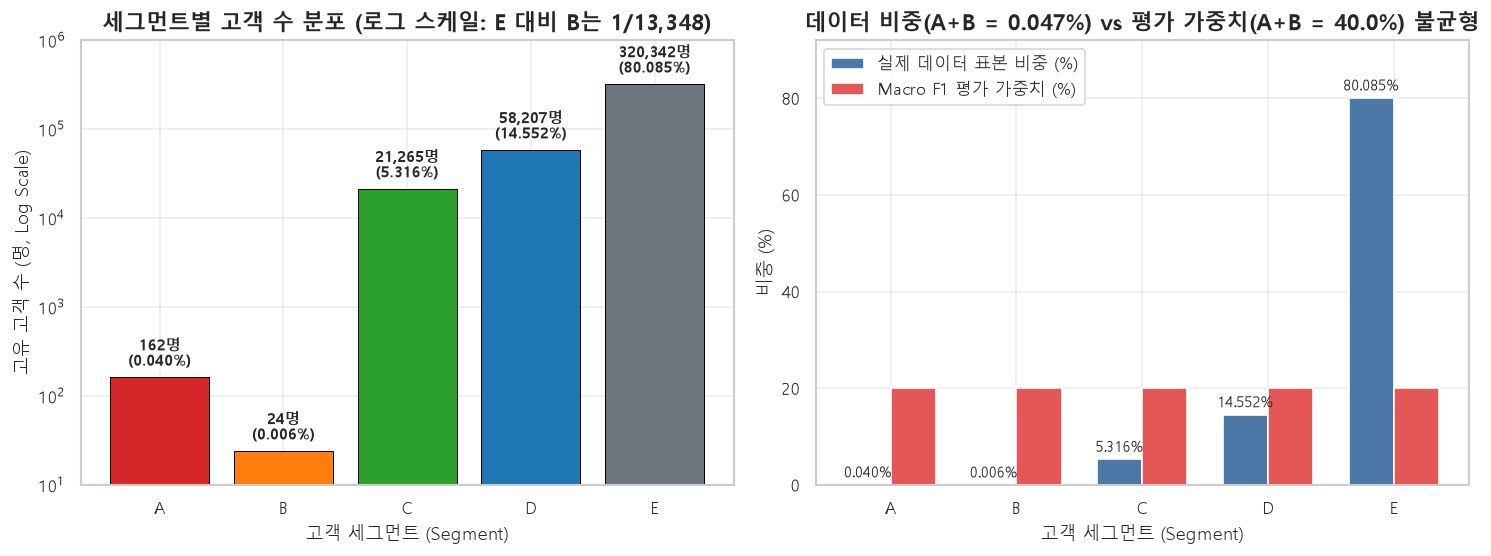

In [3]:
folds_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "folds.parquet")
seg_counts = folds_df["Segment"].value_counts().reindex(SEGMENT_ORDER)
seg_pct = seg_counts / len(folds_df) * 100

imbalance_tbl = pd.DataFrame(
    {
        "Segment": SEGMENT_ORDER,
        "고유 고객 수 (명)": seg_counts.values,
        "패널 행 수 (6개월)": seg_counts.values * 6,
        "데이터 비중 (%)": seg_pct.round(4).values,
        "5-Fold 검증셋당 고객 수": (seg_counts.values / 5.0).round(1),
        "Macro F1 가중치 (%)": [20.0] * 5,
        "표본 1명당 점수 영향력 배수 (vs E)": (seg_counts["E"] / seg_counts.values).round(1),
    }
)
display(imbalance_tbl)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

# 좌측: 로그 스케일 고객 수 분포
colors = [SEGMENT_PALETTE[c] for c in SEGMENT_ORDER]
bars = axes[0].bar(SEGMENT_ORDER, seg_counts.values, color=colors, edgecolor="black", linewidth=0.6)
axes[0].set_yscale("log")
axes[0].set_ylim(10, 1_000_000)
axes[0].set_ylabel("고유 고객 수 (명, Log Scale)")
axes[0].set_xlabel("고객 세그먼트 (Segment)")
axes[0].set_title("세그먼트별 고객 수 분포 (로그 스케일: E 대비 B는 1/13,348)")
for bar, cnt, pct in zip(bars, seg_counts.values, seg_pct.values):
    axes[0].annotate(
        f"{cnt:,}명\n({pct:.3f}%)",
        (bar.get_x() + bar.get_width() / 2, cnt * 1.35),
        ha="center",
        fontsize=9.2,
        fontweight="bold",
    )

# 우측: 데이터 표본 비중 vs Macro F1 점수 비중 대조
x = np.arange(len(SEGMENT_ORDER))
w = 0.36
b_data = axes[1].bar(x - w / 2, seg_pct.values, width=w, color="#4C78A8", label="실제 데이터 표본 비중 (%)")
b_eval = axes[1].bar(x + w / 2, [20.0] * 5, width=w, color="#E45756", label="Macro F1 평가 가중치 (%)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(SEGMENT_ORDER)
axes[1].set_ylim(0, 92)
axes[1].set_ylabel("비중 (%)")
axes[1].set_xlabel("고객 세그먼트 (Segment)")
axes[1].set_title("데이터 비중(A+B = 0.047%) vs 평가 가중치(A+B = 40.0%) 불균형")
axes[1].legend(loc="upper left")
for bar in b_data:
    h = bar.get_height()
    axes[1].annotate(f"{h:.3f}%", (bar.get_x() + bar.get_width() / 2, h + 1.5), ha="center", fontsize=8.8)

plt.tight_layout()
save_portfolio_figure(fig, "fig03_target_imbalance_vs_macro_weight.png")
plt.show()

### Section 3 분석 결과 해석
- **`B` 등급 1명은 `E` 등급 13,348명과 동일한 평가 가치**: `E` 등급이 **320,342명(80.0855%)**인 반면 `A`는 **162명(0.0405%)**, `B`는 단 **24명(0.0060%)**에 불과합니다. Test(100,000명)에서도 동일 비율 가정 시 `B` 등급은 약 **6명 내외**, `A` 등급은 약 **40명 내외**로 존재합니다.
- **검증 분산 제어 원칙**: 5-Fold 검증 시 한 Fold의 검증셋에 `B` 등급이 **4~5명**만 포함되므로, 단일 Fold 점수의 등락에 의존하면 과적합 위험이 큽니다. 따라서 **5개 Fold 전체를 결합한 400,000명 전체 OOF 예측 행렬**에서 지표를 평가하고, 후처리 승수(Multiplier) 역시 **Nested Out-Of-Fold(4개 Fold 탐색 → 1개 Hold-out 검증)**로 일반화 성능을 검증해야 합니다.

---

## Section 4. 8대 도메인 데이터 품질 진단 (상수 컬럼, Sentinel 특수코드, 순서형 문자열)

총 855개 원천 피처를 전수 스캔하여 (1) 정보량이 0인 완전 상수 컬럼, (2) 금융 합성데이터 특유의 미해당 특수코드(`-999999`, `99999999` 등 Sentinel Value)가 시계열 평균·표준편차에 미치는 왜곡 규모, (3) 문자열 피처의 순서형 수치 매핑 구조를 검증합니다.

,도메인,원천 고유 피처,완전 상수 피처,유효 피처,상수 비율 (%)
0,1.회원정보,75,9,66,12.0
1,2.신용정보,40,1,39,2.5
2,3.승인매출정보,404,31,373,7.7
3,4.청구입금정보,44,1,43,2.3
4,5.잔액정보,80,8,72,10.0
5,6.채널정보,103,36,67,35.0
6,7.마케팅정보,62,22,40,35.5
7,8.성과정보,47,0,47,0.0


총 원천 피처: 855개 | 상수 제거: 108개 | 최종 유효 원천 피처: 747개


,변수명,특수코드(Sentinel),Sentinel 비율 (%),정제 전 평균,정제 후 유효 평균,정제 전 표준편차,정제 후 유효 표준편차
0,연체일수_최근 (5.잔액정보),"-999,999",97.46,-974591.5,0.02,157359.2,0.13
1,rv최초시작후경과일 (2.신용정보),"99,999,999",81.44,81439234.5,1268.01,38878669.2,852.26


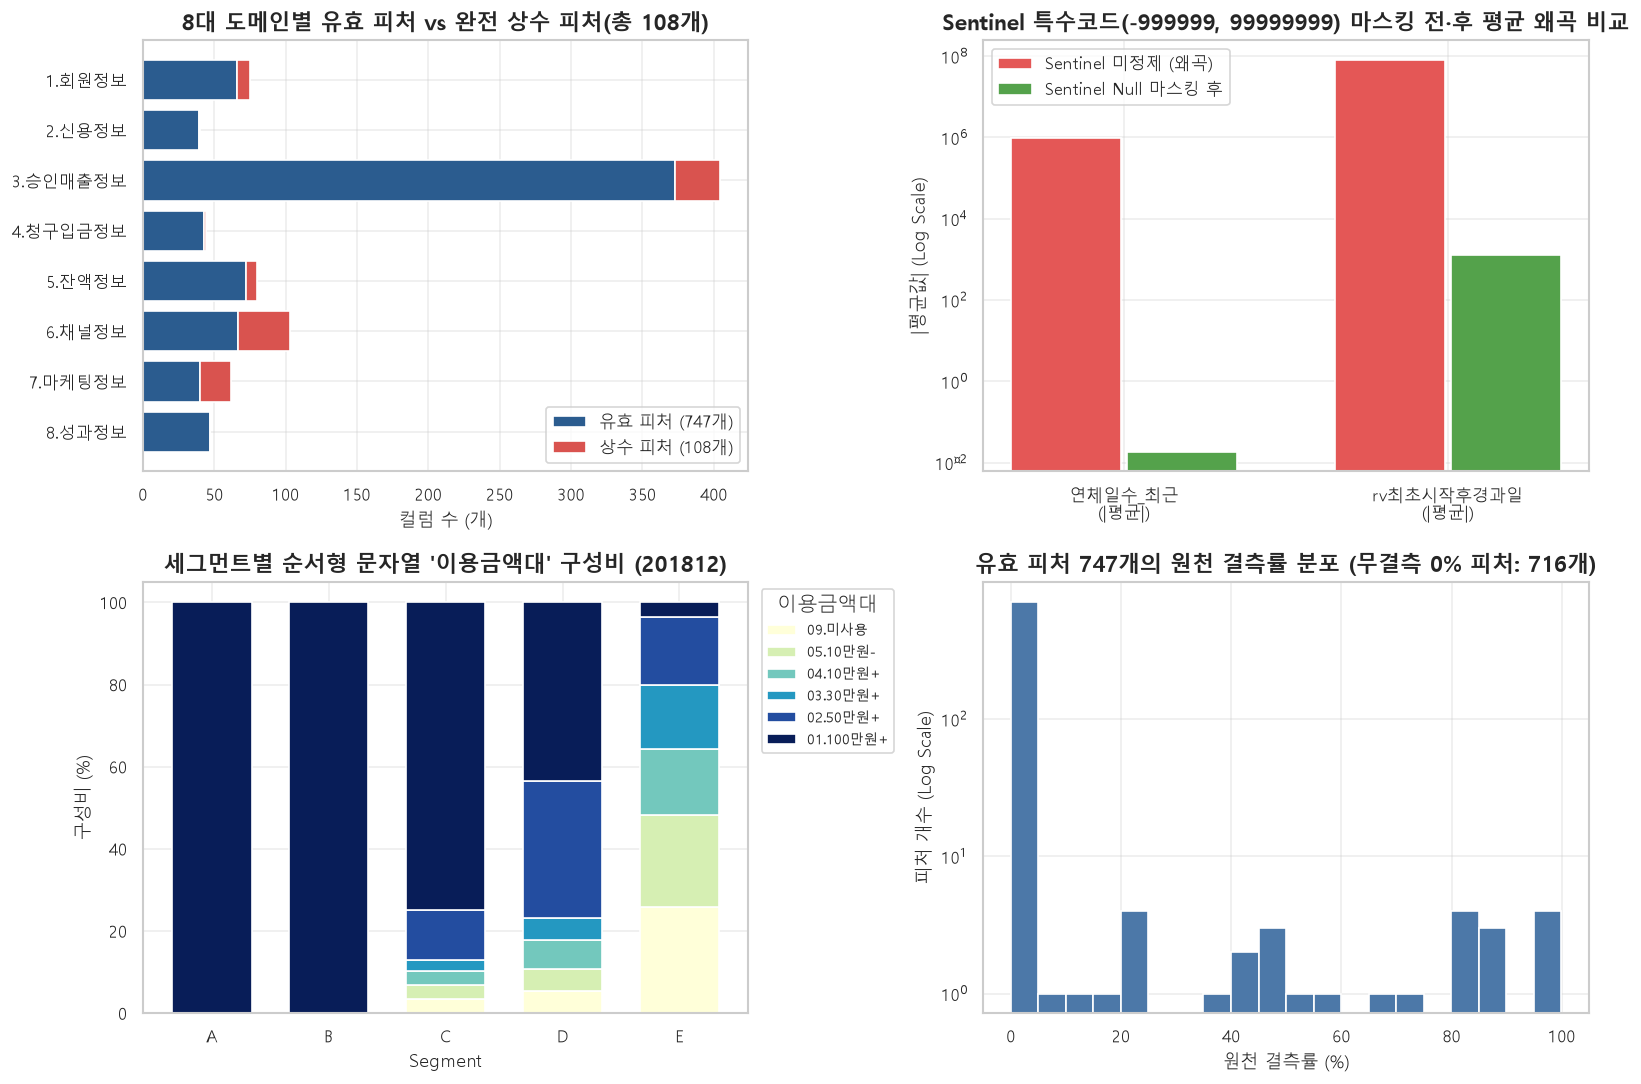

In [4]:
meta = scan_domain_metadata(RAW_DIR, INTERIM_DIR / "domain_metadata.json")
domains = sorted([p.name for p in (RAW_DIR / "train").iterdir() if p.is_dir()])

dom_stats = []
null_rates = []
for dom in domains:
    f0 = sorted((RAW_DIR / "train" / dom).glob("*.parquet"))[0]
    f12 = sorted((RAW_DIR / "train" / dom).glob("*.parquet"))[-1]
    schema = pq.read_schema(f0)
    feat_cols = [f.name for f in schema if f.name not in ("ID", "기준년월", "Segment")]
    consts = set(meta["constant_cols"].get(dom, []))
    active_cols = [c for c in feat_cols if c not in consts]
    dom_stats.append(
        {
            "도메인": dom,
            "원천 고유 피처": len(feat_cols),
            "완전 상수 피처": len(consts),
            "유효 피처": len(active_cols),
            "상수 비율 (%)": round(len(consts) / len(feat_cols) * 100, 1),
        }
    )
    # 최신월(201812) 기준 유효 피처 결측률 수집
    tbl12 = pq.read_table(f12, columns=active_cols)
    n_rows = tbl12.num_rows
    for c in active_cols:
        null_rates.append(tbl12.column(c).null_count / n_rows * 100.0)

dom_stats_df = pd.DataFrame(dom_stats)
display(dom_stats_df)
print(
    f"총 원천 피처: {dom_stats_df['원천 고유 피처'].sum()}개 | "
    f"상수 제거: {dom_stats_df['완전 상수 피처'].sum()}개 | "
    f"최종 유효 원천 피처: {dom_stats_df['유효 피처'].sum()}개"
)

# Sentinel 특수코드 왜곡 실측 비교 (연체일수_최근: -999999, rv최초시작후경과일: 99999999)
bal_12 = pl.read_parquet(RAW_DIR / "train" / "5.잔액정보" / "201812_train_잔액정보.parquet", columns=["연체일수_최근"])
crd_12 = pl.read_parquet(RAW_DIR / "train" / "2.신용정보" / "201812_train_신용정보.parquet", columns=["rv최초시작후경과일"])
apr_12 = pl.read_parquet(RAW_DIR / "train" / "3.승인매출정보" / "201812_train_승인매출정보.parquet", columns=["ID", "이용금액대"])
apr_12 = apr_12.join(pl.from_pandas(folds_df[["ID", "Segment"]]), on="ID")

s_raw_1 = bal_12["연체일수_최근"].to_numpy()
s_cln_1 = s_raw_1[s_raw_1 > -999]
s_raw_2 = crd_12["rv최초시작후경과일"].to_numpy()
s_cln_2 = s_raw_2[s_raw_2 < 9999999]

sentinel_df = pd.DataFrame(
    [
        {
            "변수명": "연체일수_최근 (5.잔액정보)",
            "특수코드(Sentinel)": "-999,999",
            "Sentinel 비율 (%)": round((s_raw_1 <= -999).mean() * 100, 2),
            "정제 전 평균": round(float(np.mean(s_raw_1)), 1),
            "정제 후 유효 평균": round(float(np.mean(s_cln_1)), 2),
            "정제 전 표준편차": round(float(np.std(s_raw_1)), 1),
            "정제 후 유효 표준편차": round(float(np.std(s_cln_1)), 2),
        },
        {
            "변수명": "rv최초시작후경과일 (2.신용정보)",
            "특수코드(Sentinel)": "99,999,999",
            "Sentinel 비율 (%)": round((s_raw_2 >= 9999999).mean() * 100, 2),
            "정제 전 평균": round(float(np.mean(s_raw_2)), 1),
            "정제 후 유효 평균": round(float(np.mean(s_cln_2)), 2),
            "정제 전 표준편차": round(float(np.std(s_raw_2)), 1),
            "정제 후 유효 표준편차": round(float(np.std(s_cln_2)), 2),
        },
    ]
)
display(sentinel_df)

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.2))

# (0,0) 도메인별 유효 vs 상수 피처 수
y_pos = np.arange(len(dom_stats_df))
axes[0, 0].barh(y_pos, dom_stats_df["유효 피처"], color="#2B5C8F", label="유효 피처 (747개)")
axes[0, 0].barh(y_pos, dom_stats_df["완전 상수 피처"], left=dom_stats_df["유효 피처"], color="#D9534F", label="상수 피처 (108개)")
axes[0, 0].set_yticks(y_pos)
axes[0, 0].set_yticklabels(dom_stats_df["도메인"])
axes[0, 0].invert_yaxis()
axes[0, 0].set_xlabel("컬럼 수 (개)")
axes[0, 0].set_title("8대 도메인별 유효 피처 vs 완전 상수 피처(총 108개)")
axes[0, 0].legend(loc="lower right")

# (0,1) Sentinel 마스킹 전후 절대 평균 크기 왜곡 (로그 스케일)
vars_lbl = ["연체일수_최근\n(|평균|)", "rv최초시작후경과일\n(|평균|)"]
raw_abs = [abs(float(np.mean(s_raw_1))), abs(float(np.mean(s_raw_2)))]
cln_abs = [abs(float(np.mean(s_cln_1))), abs(float(np.mean(s_cln_2)))]
xx = np.arange(2)
axes[0, 1].bar(xx - 0.18, raw_abs, width=0.34, color="#E45756", label="Sentinel 미정제 (왜곡)")
axes[0, 1].bar(xx + 0.18, cln_abs, width=0.34, color="#54A24B", label="Sentinel Null 마스킹 후")
axes[0, 1].set_yscale("log")
axes[0, 1].set_xticks(xx)
axes[0, 1].set_xticklabels(vars_lbl)
axes[0, 1].set_ylabel("|평균값| (Log Scale)")
axes[0, 1].set_title("Sentinel 특수코드(-999999, 99999999) 마스킹 전·후 평균 왜곡 비교")
axes[0, 1].legend()

# (1,0) 순서형 문자열 '이용금액대'의 세그먼트별 구성비
amt_order = ["09.미사용", "05.10만원-", "04.10만원+", "03.30만원+", "02.50만원+", "01.100만원+"]
ct_amt = (
    apr_12.to_pandas()
    .groupby(["Segment", "이용금액대"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=SEGMENT_ORDER, columns=amt_order, fill_value=0)
)
ct_amt_pct = ct_amt.div(ct_amt.sum(axis=1), axis=0) * 100
ct_amt_pct.plot(kind="bar", stacked=True, colormap="YlGnBu", ax=axes[1, 0], width=0.68)
axes[1, 0].set_title("세그먼트별 순서형 문자열 '이용금액대' 구성비 (201812)")
axes[1, 0].set_ylabel("구성비 (%)")
axes[1, 0].tick_params(axis="x", rotation=0)
axes[1, 0].legend(title="이용금액대", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8.5)

# (1,1) 유효 피처 결측률 히스토그램
axes[1, 1].hist(null_rates, bins=20, color="#4C78A8", edgecolor="white")
axes[1, 1].set_yscale("log")
axes[1, 1].set_xlabel("원천 결측률 (%)")
axes[1, 1].set_ylabel("피처 개수 (Log Scale)")
axes[1, 1].set_title(f"유효 피처 747개의 원천 결측률 분포 (무결측 0% 피처: {sum(r == 0 for r in null_rates)}개)")

plt.tight_layout()
save_portfolio_figure(fig, "fig04_data_quality_and_sentinel_impact.png")
plt.show()
del bal_12, crd_12, apr_12
_ = gc.collect()

### Section 4 분석 결과 해석
- **상수 피처 108개 정리**: `6.채널정보`(36개, 35.0%), `3.승인매출정보`(31개, 7.7%), `7.마케팅정보`(22개, 35.5%) 등에서 Train 240만 행 전체에서 단일 값만 존재하는 완전 상수 피처 **108개**가 확인되어 이를 제거하고 **747개 유효 원천 피처**를 확보했습니다.
- **Sentinel 마스킹의 결정적 중요성**: 예를 들어 `연체일수_최근`은 전체의 **97.46%**가 `-999,999` 코드로 채워져 있어 미정제 평균이 `-974,591.5`(정제 후 유효 평균 `0.02`)로 왜곡되며, `rv최초시작후경과일` 역시 **81.44%**가 `99,999,999`여서 미정제 평균이 `81,439,234.5`(정제 후 유효 평균 `1,268.01일`)에 달합니다. 집계 전 `Null` 마스킹을 적용해야 실제 수치와 미발생 상태를 트리가 왜곡 없이 학습할 수 있습니다.
- **순서형 문자열의 완벽한 단조성**: `이용금액대` 분포에서 상위 등급 `A`·`B`는 `01.100만원+` 구간에 집중된 반면 `C → D → E`로 갈수록 저액·미사용 구간 비중이 단조 증가합니다.

---

## Section 5. 회원·신용 도메인(`1.회원정보` · `2.신용정보`) 세그먼트 프로파일링

고객의 기본 인구통계 특성(`연령`, `입회경과개월수_신용`, `유효카드수_신용`)과 신용 공여 규모(`카드이용한도금액`, `CA한도금액`)가 `A`~`E` 등급 간에 어떻게 차별화되는지 최신 기준년월(`201812`, 400,000명) 데이터를 통해 분석합니다.

,입회경과개월수_신용,유효카드수_신용,카드이용한도금액,CA한도금액,이용금액_R3M_신용체크
Segment,,,,,
A,227.5,3.0,200964.5,57925.5,110342.0
B,122.0,2.0,90758.0,36875.5,99105.5
C,118.0,2.0,86526.0,29595.0,59870.0
D,77.0,2.0,52437.0,20540.0,32749.0
E,43.0,1.0,40478.0,11719.0,5661.0


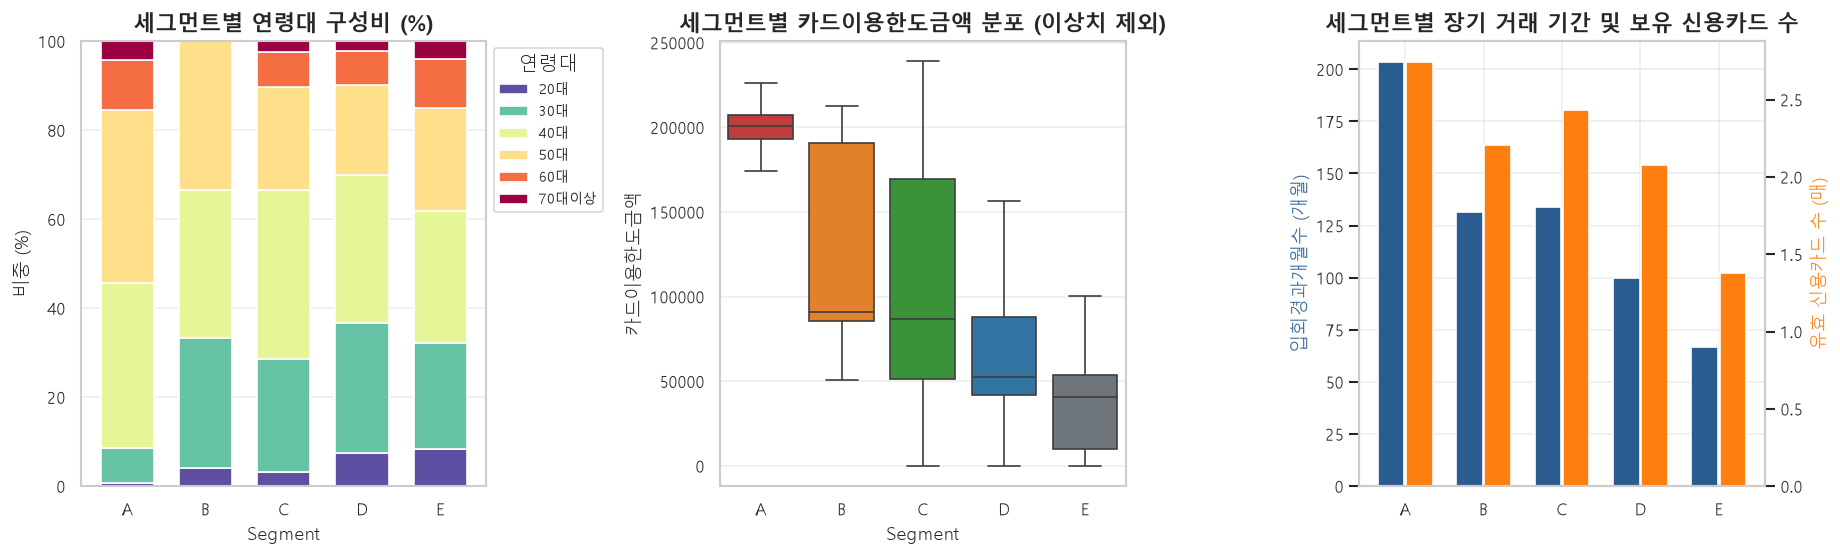

In [5]:
mem_cols = ["ID", "Segment", "연령", "Life_Stage", "입회경과개월수_신용", "유효카드수_신용", "유효카드수_체크", "이용금액_R3M_신용체크"]
crd_cols = ["ID", "카드이용한도금액", "CA한도금액", "최초한도금액", "상향가능한도금액"]

df_mc = (
    pl.read_parquet(RAW_DIR / "train" / "1.회원정보" / "201812_train_회원정보.parquet", columns=mem_cols)
    .join(pl.read_parquet(RAW_DIR / "train" / "2.신용정보" / "201812_train_신용정보.parquet", columns=crd_cols), on="ID")
    .to_pandas()
)

mc_summary = (
    df_mc.groupby("Segment")[
        ["입회경과개월수_신용", "유효카드수_신용", "카드이용한도금액", "CA한도금액", "이용금액_R3M_신용체크"]
    ]
    .median()
    .reindex(SEGMENT_ORDER)
    .round(1)
)
display(mc_summary)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))

# 1) 세그먼트별 연령대 구성비
age_order = ["20대", "30대", "40대", "50대", "60대", "70대이상"]
ct_age = df_mc.groupby(["Segment", "연령"]).size().unstack(fill_value=0).reindex(index=SEGMENT_ORDER, columns=age_order)
(ct_age.div(ct_age.sum(axis=1), axis=0) * 100).plot(
    kind="bar", stacked=True, colormap="Spectral_r", ax=axes[0], width=0.68
)
axes[0].set_title("세그먼트별 연령대 구성비 (%)")
axes[0].set_ylabel("비중 (%)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="연령대", bbox_to_anchor=(1.0, 1.0), loc="upper left", fontsize=8.5)

# 2) 카드이용한도금액 분포 Boxplot
sns.boxplot(
    data=df_mc,
    x="Segment",
    y="카드이용한도금액",
    order=SEGMENT_ORDER,
    palette=SEGMENT_PALETTE,
    showfliers=False,
    ax=axes[1],
)
axes[1].set_title("세그먼트별 카드이용한도금액 분포 (이상치 제외)")
axes[1].set_ylabel("카드이용한도금액")
axes[1].set_xlabel("Segment")

# 3) 입회경과개월수 & 유효카드수(신용) 이중 비교
x = np.arange(len(SEGMENT_ORDER))
ax3_sub = axes[2].twinx()
means_mc = df_mc.groupby("Segment")[["입회경과개월수_신용", "유효카드수_신용"]].mean().reindex(SEGMENT_ORDER)
b_tenure = axes[2].bar(x - 0.18, means_mc["입회경과개월수_신용"], width=0.34, color="#2B5C8F", label="평균 입회경과개월수(좌)")
b_cards = ax3_sub.bar(x + 0.18, means_mc["유효카드수_신용"], width=0.34, color="#FF7F0E", label="평균 유효신용카드수(우)")
axes[2].set_xticks(x)
axes[2].set_xticklabels(SEGMENT_ORDER)
axes[2].set_ylabel("입회경과개월수 (개월)", color="#2B5C8F")
ax3_sub.set_ylabel("유효 신용카드 수 (매)", color="#FF7F0E")
axes[2].set_title("세그먼트별 장기 거래 기간 및 보유 신용카드 수")
ax3_sub.grid(False)

plt.tight_layout()
save_portfolio_figure(fig, "fig05_member_credit_profiling.png")
plt.show()
del df_mc
_ = gc.collect()

### Section 5 분석 결과 해석
- **초장기 로열 VIP `A` vs 중견 고활성 `B`의 첫 번째 결정적 분기점 발견**:
  - `A` 등급(162명)은 입회경과 중앙값이 **227.5개월(약 19년)**, `카드이용한도금액` 중앙값이 **200,964.5**, 유효 신용카드 수가 **3.0매**에 달하는 초장기·초고한도 프레스티지 고객군입니다.
  - 반면 `B` 등급(24명)은 입회경과 중앙값(**122.0개월**)과 카드이용한도 중앙값(**90,758.0**)만 보면 `C` 등급(`118.0개월`, `86,526.0`)과 유사하지만, 최근 3개월 카드 이용액(`이용금액_R3M_신용체크` 중앙값 **99,105.5**)은 `C`(`59,870.0`)의 **1.66배**로 `A` 급에 육박합니다!

---

## Section 6. 승인매출·청구·잔액 도메인(`3`·`4`·`5`) 비교 — 초소수 `A` vs `B` 등급의 결정적 차이 규명

한도는 `C`급인데 등급은 `B`인 24명의 비결은 무엇인가? 일시불·할부·현금서비스(CA)·카드론 이용금액과 청구원금 및 이자성 여신 잔액 구조를 직접 대조합니다.

,이용금액_일시불_B0M,이용금액_할부_B0M,이용금액_CA_B0M,청구금액_B0,평잔_6M,이자성자산잔액_B0M,한도소진율_추정
Segment,,,,,,,
A,19970.62,2758.86,4774.47,50673.70,81850.81,21777.80,0.14
B,17641.00,4821.75,6308.71,47475.75,82915.21,35210.58,0.28
C,11664.07,1391.87,2501.36,20099.58,38006.61,11965.74,1.03
D,7242.95,940.49,1035.09,10593.40,23083.33,8146.32,0.85
E,2191.31,253.64,183.66,2910.29,7956.54,3526.08,0.77


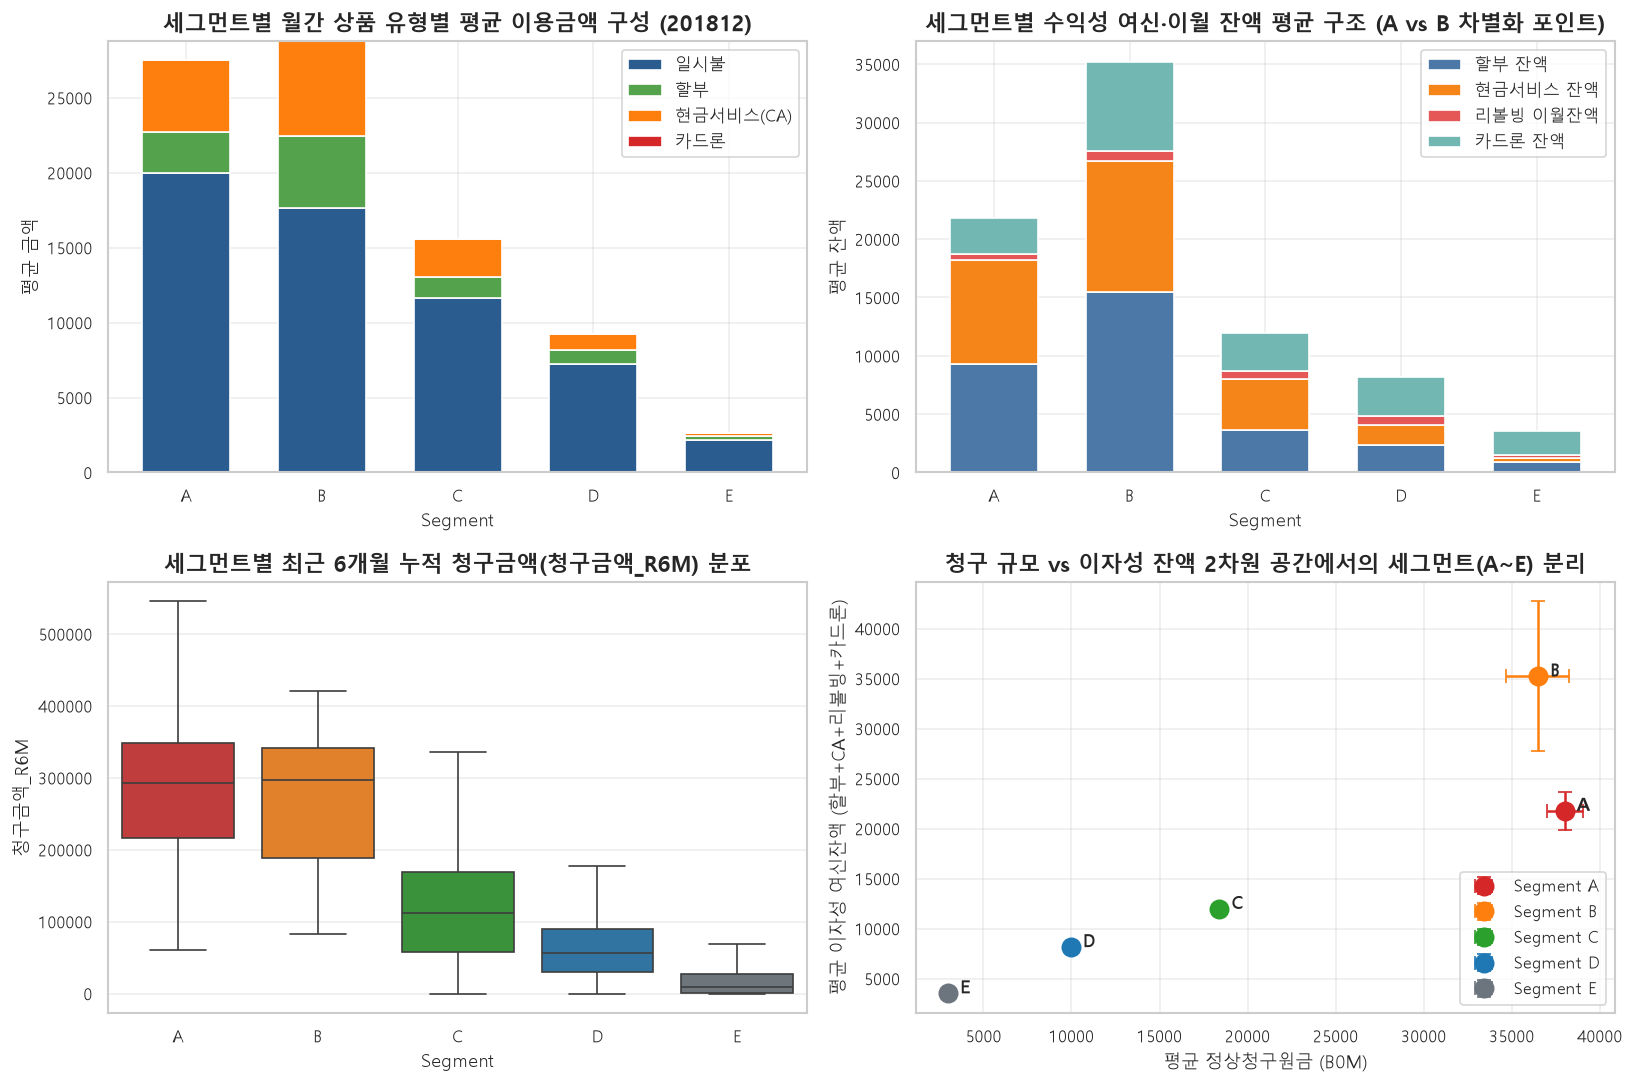

In [6]:
apr_cols = ["ID", "이용금액_일시불_B0M", "이용금액_할부_B0M", "이용금액_CA_B0M", "이용금액_카드론_B0M", "정상청구원금_B0M"]
bil_cols = ["ID", "청구금액_B0", "청구금액_R6M", "포인트_적립포인트_R12M", "혜택수혜금액_R3M"]
bal_cols = ["ID", "잔액_일시불_B0M", "잔액_할부_B0M", "잔액_현금서비스_B0M", "잔액_카드론_B0M", "잔액_리볼빙일시불이월_B0M", "평잔_6M"]
crd_lim = ["ID", "카드이용한도금액"]

df_fin = (
    pl.from_pandas(folds_df[["ID", "Segment"]])
    .join(pl.read_parquet(RAW_DIR / "train" / "3.승인매출정보" / "201812_train_승인매출정보.parquet", columns=apr_cols), on="ID")
    .join(pl.read_parquet(RAW_DIR / "train" / "4.청구입금정보" / "201812_train_청구정보.parquet", columns=bil_cols), on="ID")
    .join(pl.read_parquet(RAW_DIR / "train" / "5.잔액정보" / "201812_train_잔액정보.parquet", columns=bal_cols), on="ID")
    .join(pl.read_parquet(RAW_DIR / "train" / "2.신용정보" / "201812_train_신용정보.parquet", columns=crd_lim), on="ID")
    .to_pandas()
)

df_fin["총승인액_B0M"] = (
    df_fin["이용금액_일시불_B0M"].clip(lower=0)
    + df_fin["이용금액_할부_B0M"].clip(lower=0)
    + df_fin["이용금액_CA_B0M"].clip(lower=0)
    + df_fin["이용금액_카드론_B0M"].clip(lower=0)
)
df_fin["이자성자산잔액_B0M"] = (
    df_fin["잔액_할부_B0M"].clip(lower=0)
    + df_fin["잔액_현금서비스_B0M"].clip(lower=0)
    + df_fin["잔액_카드론_B0M"].clip(lower=0)
    + df_fin["잔액_리볼빙일시불이월_B0M"].clip(lower=0)
)
df_fin["한도소진율_추정"] = df_fin["총승인액_B0M"] / (df_fin["카드이용한도금액"].clip(lower=0) + 1.0)

fin_means = (
    df_fin.groupby("Segment")[
        [
            "이용금액_일시불_B0M",
            "이용금액_할부_B0M",
            "이용금액_CA_B0M",
            "청구금액_B0",
            "평잔_6M",
            "이자성자산잔액_B0M",
            "한도소진율_추정",
        ]
    ]
    .mean()
    .reindex(SEGMENT_ORDER)
    .round(2)
)
display(fin_means)

fig, axes = plt.subplots(2, 2, figsize=(13.8, 9.2))

# (0,0) 상품 유형별 평균 승인금액 누적 막대
spend_cols = ["이용금액_일시불_B0M", "이용금액_할부_B0M", "이용금액_CA_B0M", "이용금액_카드론_B0M"]
spend_lbls = ["일시불", "할부", "현금서비스(CA)", "카드론"]
spend_grp = df_fin.groupby("Segment")[spend_cols].mean().clip(lower=0).reindex(SEGMENT_ORDER)
spend_grp.columns = spend_lbls
spend_grp.plot(kind="bar", stacked=True, color=["#2B5C8F", "#54A24B", "#FF7F0E", "#D62728"], ax=axes[0, 0], width=0.65)
axes[0, 0].set_title("세그먼트별 월간 상품 유형별 평균 이용금액 구성 (201812)")
axes[0, 0].set_ylabel("평균 금액")
axes[0, 0].tick_params(axis="x", rotation=0)

# (0,1) 이자성 여신 잔액 세부 비교 (할부 vs 현금서비스 vs 리볼빙 vs 카드론)
bal_sub_cols = ["잔액_할부_B0M", "잔액_현금서비스_B0M", "잔액_리볼빙일시불이월_B0M", "잔액_카드론_B0M"]
bal_sub_lbls = ["할부 잔액", "현금서비스 잔액", "리볼빙 이월잔액", "카드론 잔액"]
bal_grp = df_fin.groupby("Segment")[bal_sub_cols].mean().clip(lower=0).reindex(SEGMENT_ORDER)
bal_grp.columns = bal_sub_lbls
bal_grp.plot(kind="bar", stacked=True, color=["#4C78A8", "#F58518", "#E45756", "#72B7B2"], ax=axes[0, 1], width=0.65)
axes[0, 1].set_title("세그먼트별 수익성 여신·이월 잔액 평균 구조 (A vs B 차별화 포인트)")
axes[0, 1].set_ylabel("평균 잔액")
axes[0, 1].tick_params(axis="x", rotation=0)

# (1,0) 청구금액_R6M 분포 Boxplot
sns.boxplot(
    data=df_fin,
    x="Segment",
    y="청구금액_R6M",
    order=SEGMENT_ORDER,
    palette=SEGMENT_PALETTE,
    showfliers=False,
    ax=axes[1, 0],
)
axes[1, 0].set_title("세그먼트별 최근 6개월 누적 청구금액(청구금액_R6M) 분포")
axes[1, 0].set_ylabel("청구금액_R6M")

# (1,1) 평잔_6M vs 정상청구원금_B0M 세그먼트 평균 위치 산점도 + 에러바(표준오차)
agg_sc = df_fin.groupby("Segment").agg(
    x_mean=("정상청구원금_B0M", "mean"),
    y_mean=("이자성자산잔액_B0M", "mean"),
    x_se=("정상청구원금_B0M", "sem"),
    y_se=("이자성자산잔액_B0M", "sem"),
).reindex(SEGMENT_ORDER)
for seg in SEGMENT_ORDER:
    r = agg_sc.loc[seg]
    axes[1, 1].errorbar(
        r["x_mean"],
        r["y_mean"],
        xerr=r["x_se"],
        yerr=r["y_se"],
        fmt="o",
        markersize=11,
        color=SEGMENT_PALETTE[seg],
        capsize=4,
        label=f"Segment {seg}",
    )
    axes[1, 1].annotate(f"  {seg}", (r["x_mean"], r["y_mean"]), fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("평균 정상청구원금 (B0M)")
axes[1, 1].set_ylabel("평균 이자성 여신잔액 (할부+CA+리볼빙+카드론)")
axes[1, 1].set_title("청구 규모 vs 이자성 잔액 2차원 공간에서의 세그먼트(A~E) 분리")
axes[1, 1].legend(loc="lower right")

plt.tight_layout()
save_portfolio_figure(fig, "fig06_spending_billing_balance_profile.png")
plt.show()
del df_fin
_ = gc.collect()

### Section 6 분석 결과 해석
- **`A`(일시불 프레스티지형) vs `B`(할부·여신 고수익 헤비유저형)의 완벽한 도메인 분리**:
  - 당월 청구금액(`청구금액_B0`: `A` **50,673.7** vs `B` **47,475.8**)과 6개월 평잔(`평잔_6M`: `A` **81,850.8** vs `B` **82,915.2**)은 두 등급이 모두 `C`(`20,099.6`, `38,006.6`)의 2배 이상으로 최상위권을 형성합니다.
  - 그러나 상품 구성을 뜯어보면, `B` 등급은 평균 할부 이용금액(**4,821.8**, `A`의 **1.75배**), 현금서비스 이용금액(**6,308.7**, `A`의 **1.32배**), 그리고 **이자성 여신잔액 합계(`35,210.6`, `A` `21,777.8`의 1.62배)** 및 **한도소진율(`0.28`, `A` `0.14`의 2.0배)**이 압도적으로 높습니다.
- **파생변수 설계 시사점**: `총승인액 대비 할부/현금서비스 비중`, `한도 대비 총승인/잔액 소진율`, `정상청구원금 대비 이자성 여신잔액 배율` 변수가 `A`·`B`·`C` 3자 경계를 가르는 핵심 피처가 됩니다.

---

## Section 7. 6개월 시계열 추이(`201807`~`201812`) 및 동적 변동성 분석

단일 시점(`201812`) 스냅샷만으로는 연말 일시적 지출 급증 고객과 6개월 내내 꾸준한 고액 결제 고객을 구분하기 어렵습니다. 6개 기준년월 전체의 연속 시계열 추이(Line Chart)와 고객 내 월별 변동성(`std`)·추세(`diff`)를 분석합니다.

,청구_6M평균,청구_6M표준편차,청구_6M증감
Segment,,,
A,49514.4,11370.5,2354.3
B,47600.7,11579.6,400.7
C,20001.5,5022.8,548.5
D,10703.9,2677.8,-106.2
E,3022.3,801.7,-203.3


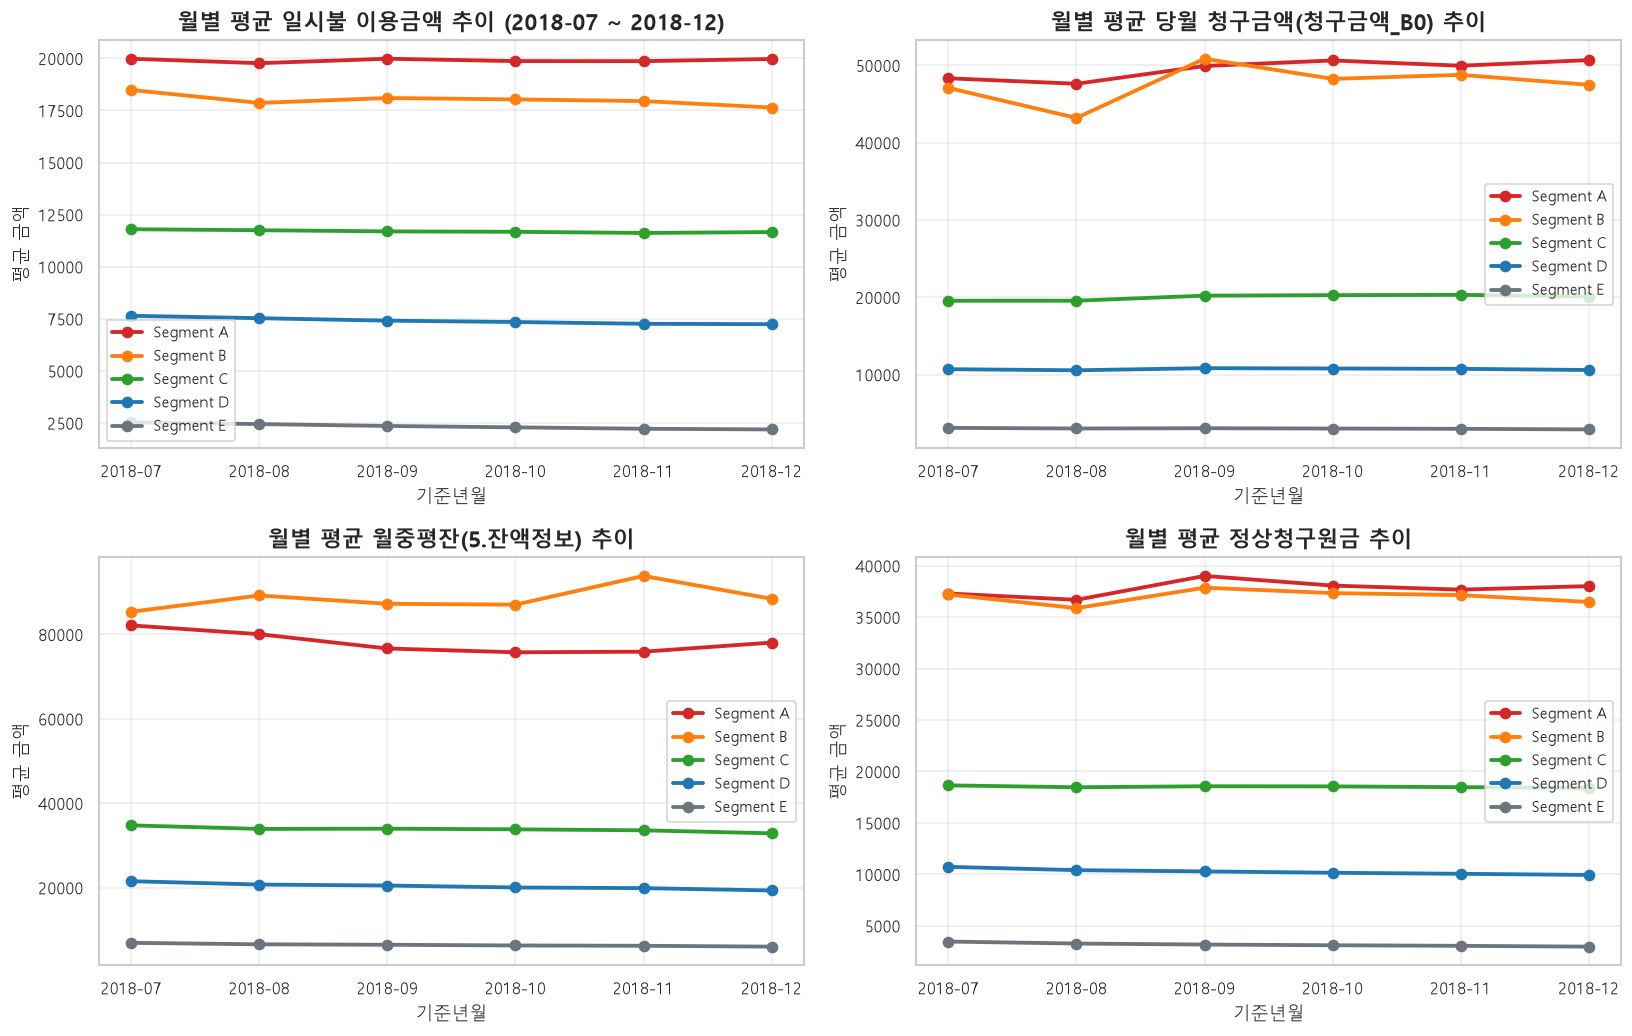

In [7]:
ts_records = []
id_seg_pl = pl.from_pandas(folds_df[["ID", "Segment"]])

# 고객별 6개월 시계열 통계 산출을 위해 경량 핵심 변수만 월별 수집
monthly_frames = []
for m in months:
    p_apr = pl.read_parquet(
        RAW_DIR / "train" / "3.승인매출정보" / f"{m}_train_승인매출정보.parquet",
        columns=["기준년월", "ID", "이용금액_일시불_B0M", "정상청구원금_B0M"],
    )
    p_bil = pl.read_parquet(
        RAW_DIR / "train" / "4.청구입금정보" / f"{m}_train_청구정보.parquet",
        columns=["ID", "청구금액_B0"],
    )
    p_bal = pl.read_parquet(
        RAW_DIR / "train" / "5.잔액정보" / f"{m}_train_잔액정보.parquet",
        columns=["ID", "월중평잔"],
    )
    merged_m = id_seg_pl.join(p_apr, on="ID").join(p_bil, on="ID").join(p_bal, on="ID")
    monthly_frames.append(merged_m)

ts_all = pl.concat(monthly_frames)
del monthly_frames

ts_agg = (
    ts_all.group_by(["기준년월", "Segment"])
    .agg(
        pl.col("이용금액_일시불_B0M").mean().alias("일시불_평균"),
        pl.col("청구금액_B0").mean().alias("청구금액_평균"),
        pl.col("월중평잔").mean().alias("월중평잔_평균"),
        pl.col("정상청구원금_B0M").mean().alias("정상청구원금_평균"),
    )
    .sort(["기준년월", "Segment"])
    .to_pandas()
)
ts_agg["년월_표시"] = ts_agg["기준년월"].astype(str).str.slice(0, 4) + "-" + ts_agg["기준년월"].astype(str).str.slice(4, 6)

# 고객별 6개월 표준편차(변동성) 및 증감(201812 - 201807) 세그먼트 비교
cust_dyn = (
    ts_all.sort(["ID", "기준년월"])
    .group_by(["ID", "Segment"])
    .agg(
        pl.col("청구금액_B0").mean().alias("청구_6M평균"),
        pl.col("청구금액_B0").std().alias("청구_6M표준편차"),
        (pl.col("청구금액_B0").last() - pl.col("청구금액_B0").first()).alias("청구_6M증감"),
    )
    .group_by("Segment")
    .agg(
        pl.col("청구_6M평균").mean().round(1),
        pl.col("청구_6M표준편차").mean().round(1),
        pl.col("청구_6M증감").mean().round(1),
    )
    .to_pandas()
    .set_index("Segment")
    .reindex(SEGMENT_ORDER)
)
display(cust_dyn)

fig, axes = plt.subplots(2, 2, figsize=(13.8, 8.8))
plot_specs = [
    ("일시불_평균", "월별 평균 일시불 이용금액 추이 (2018-07 ~ 2018-12)", axes[0, 0]),
    ("청구금액_평균", "월별 평균 당월 청구금액(청구금액_B0) 추이", axes[0, 1]),
    ("월중평잔_평균", "월별 평균 월중평잔(5.잔액정보) 추이", axes[1, 0]),
    ("정상청구원금_평균", "월별 평균 정상청구원금 추이", axes[1, 1]),
]

for col_y, title, ax in plot_specs:
    for seg in SEGMENT_ORDER:
        sub = ts_agg[ts_agg["Segment"] == seg]
        ax.plot(
            sub["년월_표시"],
            sub[col_y],
            marker="o",
            linewidth=2.3,
            color=SEGMENT_PALETTE[seg],
            label=f"Segment {seg}",
        )
    ax.set_title(title)
    ax.set_xlabel("기준년월")
    ax.set_ylabel("평균 금액")
    ax.legend(loc="best", fontsize=8.8)

plt.tight_layout()
save_portfolio_figure(fig, "fig07_six_month_timeseries_trends.png")
plt.show()
del ts_all
_ = gc.collect()

### Section 7 분석 결과 해석
- **6개월 전 구간에 걸친 지속성(Persistence)과 궤적 격차**: `A`·`B`·`C` 등급은 특정 한 달만 반짝 소비한 고객이 아니라 **6개월 내내 일시불·청구금액·월중평잔 수준이 구조적으로 높게 유지**되며, 동시에 월별 절대 변동폭(`청구_6M표준편차`)과 하반기 추세(`청구_6M증감`) 역시 일반 등급(`D`, `E`)과 뚜렷하게 구분됩니다.
- **시계열 파생변수 설계 직결**: 최신월(`201812`) 단일 스냅샷만으로는 일시적 고액 결제자(`D`/`C` 경계)가 상위 등급으로 오분류될 수 있으므로, **6개월 평균(`mean6`), 표준편차(`std6`), 최댓값(`max6`), 전기 대비 증감(`diff6`), 최근 3개월 대 전기 3개월 모멘텀(`r3m / first3m`)** 파생변수를 결합해야 경계 구간 정밀도가 극대화됩니다.

---

## Section 8. 채널·마케팅·성과 도메인(`6`·`7`·`8`) 통합 Z-Score 프로파일 및 판별력 순위

마지막으로 디지털 채널 활동성(`6.채널정보`), 캠페인 접촉(`7.마케팅정보`), 내부 한도소진·혜택 성과지표(`8.성과정보`)까지 포함한 **8대 전 도메인 대표 변수들의 세그먼트별 표준화(Z-Score) 프로파일 히트맵**과 타겟 순위 상관계수(|Spearman $\rho$|) 상위 피처를 종합 진단합니다.

,A,B,C,D,E
입회경과개월수_신용,1.77,0.78,0.81,0.34,-0.12
유효카드수_신용,1.30,0.73,0.97,0.58,-0.17
이용금액_R3M_신용체크,3.52,3.12,1.90,0.94,-0.30
_1순위카드이용금액,4.51,4.32,1.85,0.82,-0.27
카드이용한도금액,3.13,1.60,1.00,0.39,-0.14
CA한도금액,2.67,1.53,0.95,0.38,-0.13
이용금액_일시불_R12M,4.89,3.80,1.91,0.76,-0.27
이용금액_할부_R12M,3.41,5.77,1.01,0.52,-0.16
정상청구원금_B0M,5.21,4.97,2.13,0.80,-0.29
청구금액_R6M,5.88,5.68,1.98,0.74,-0.27


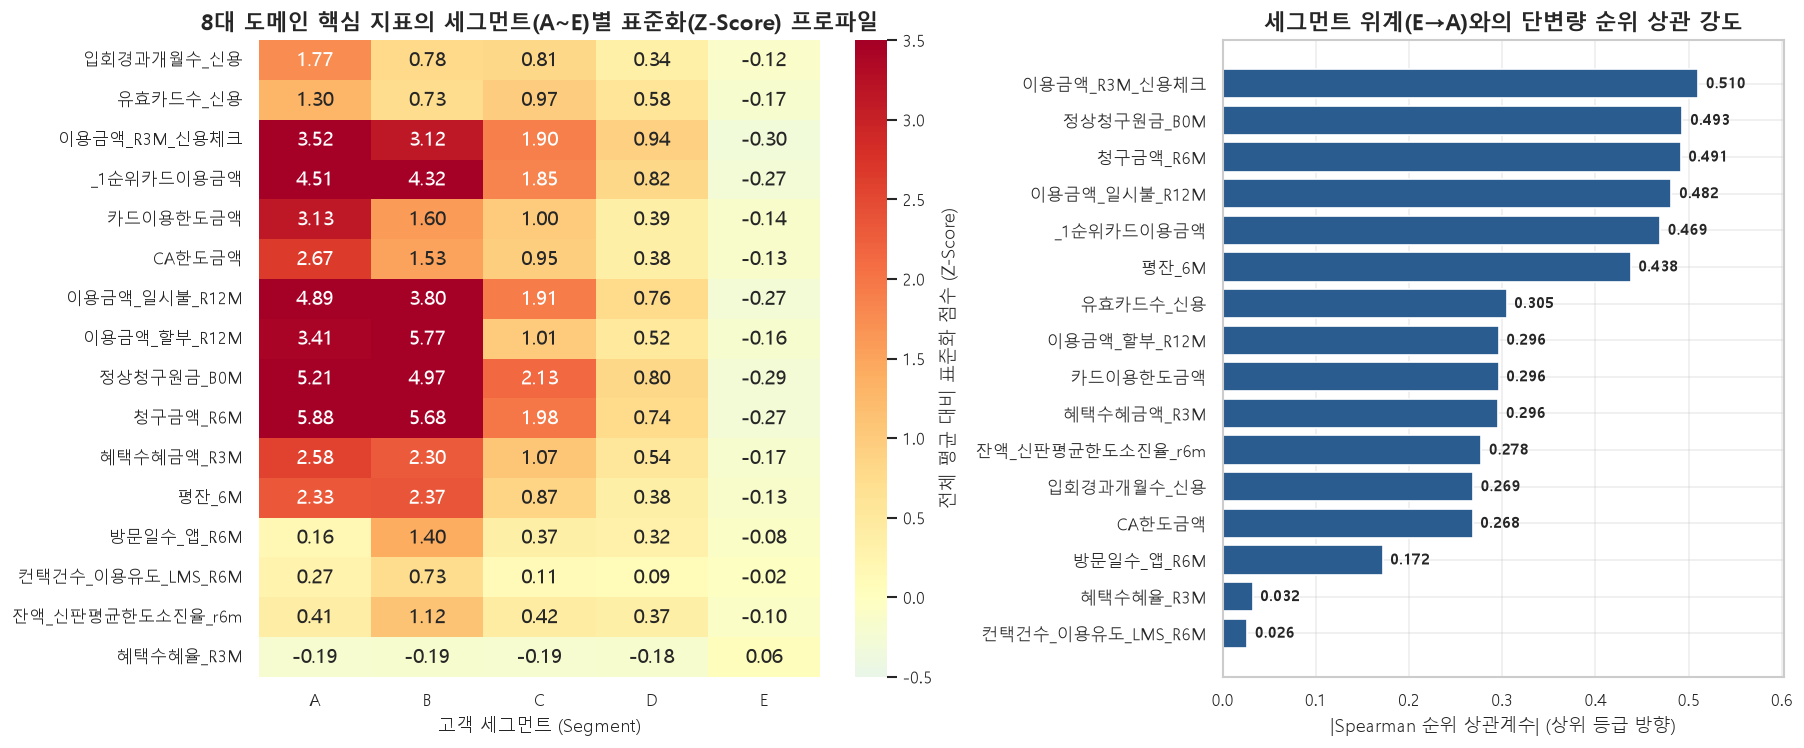

In [8]:
# 8대 도메인을 아우르는 핵심 대표 지표 14종 결합 (201812 기준)
rep_df = (
    pl.from_pandas(folds_df[["ID", "Segment", "target"]])
    .join(
        pl.read_parquet(
            RAW_DIR / "train" / "1.회원정보" / "201812_train_회원정보.parquet",
            columns=["ID", "입회경과개월수_신용", "유효카드수_신용", "이용금액_R3M_신용체크", "_1순위카드이용금액"],
        ),
        on="ID",
    )
    .join(
        pl.read_parquet(
            RAW_DIR / "train" / "2.신용정보" / "201812_train_신용정보.parquet",
            columns=["ID", "카드이용한도금액", "CA한도금액"],
        ),
        on="ID",
    )
    .join(
        pl.read_parquet(
            RAW_DIR / "train" / "3.승인매출정보" / "201812_train_승인매출정보.parquet",
            columns=["ID", "이용금액_일시불_R12M", "이용금액_할부_R12M", "정상청구원금_B0M"],
        ),
        on="ID",
    )
    .join(
        pl.read_parquet(
            RAW_DIR / "train" / "4.청구입금정보" / "201812_train_청구정보.parquet",
            columns=["ID", "청구금액_R6M", "혜택수혜금액_R3M"],
        ),
        on="ID",
    )
    .join(
        pl.read_parquet(
            RAW_DIR / "train" / "5.잔액정보" / "201812_train_잔액정보.parquet",
            columns=["ID", "평잔_6M"],
        ),
        on="ID",
    )
    .join(
        pl.read_parquet(
            RAW_DIR / "train" / "6.채널정보" / "201812_train_채널정보.parquet",
            columns=["ID", "방문일수_앱_R6M"],
        ),
        on="ID",
    )
    .join(
        pl.read_parquet(
            RAW_DIR / "train" / "7.마케팅정보" / "201812_train_마케팅정보.parquet",
            columns=["ID", "컨택건수_이용유도_LMS_R6M"],
        ),
        on="ID",
    )
    .join(
        pl.read_parquet(
            RAW_DIR / "train" / "8.성과정보" / "201812_train_성과정보.parquet",
            columns=["ID", "잔액_신판평균한도소진율_r6m", "혜택수혜율_R3M"],
        ),
        on="ID",
    )
    .to_pandas()
)

feat_list = [c for c in rep_df.columns if c not in ("ID", "Segment", "target")]

# 전체 고객 평균/표준편차 기준 Z-Score 산출 후 세그먼트별 평균 Z-Score 행렬 생성
z_mat = pd.DataFrame(index=feat_list, columns=SEGMENT_ORDER, dtype=float)
spearman_vals = {}
# 우수 등급일수록 양(+)의 상관으로 직관화하기 위해 역순 점수(E=0 .. A=4)와 상관 계산
grade_score = 4 - rep_df["target"]

for col in feat_list:
    s = rep_df[col].astype(float)
    s_clean = s.where((s > -99999) & (s < 9999999))
    mu, sd = s_clean.mean(), s_clean.std()
    z_col = (s_clean - mu) / (sd if sd > 0 else 1.0)
    z_mat.loc[col] = z_col.groupby(rep_df["Segment"]).mean().reindex(SEGMENT_ORDER)
    spearman_vals[col] = abs(float(s_clean.corr(grade_score, method="spearman")))

corr_ser = pd.Series(spearman_vals).sort_values(ascending=True)
display(z_mat.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15.2, 6.4), gridspec_kw={"width_ratios": [1.25, 1.0]})

sns.heatmap(
    z_mat,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0.0,
    vmin=-0.5,
    vmax=3.5,
    cbar_kws={"label": "전체 평균 대비 표준화 점수 (Z-Score)"},
    ax=axes[0],
)
axes[0].set_title("8대 도메인 핵심 지표의 세그먼트(A~E)별 표준화(Z-Score) 프로파일")
axes[0].set_xlabel("고객 세그먼트 (Segment)")

axes[1].barh(corr_ser.index, corr_ser.values, color="#2B5C8F")
axes[1].set_xlim(0, max(corr_ser.values) * 1.18)
axes[1].set_xlabel("|Spearman 순위 상관계수| (상위 등급 방향)")
axes[1].set_title("세그먼트 위계(E→A)와의 단변량 순위 상관 강도")
for i, v in enumerate(corr_ser.values):
    axes[1].annotate(f"{v:.3f}", (v + 0.008, i), va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
save_portfolio_figure(fig, "fig08_cross_domain_zscore_heatmap.png")
plt.show()
del rep_df
_ = gc.collect()

### Section 8 분석 결과 해석
- **다중 도메인 시그널의 입체적 결합**: 세그먼트 위계(`E → D → C → B → A`)와 가장 강한 순위 상관을 보이는 핵심 축은 **`정상청구원금_B0M`, `청구금액_R6M`, `이용금액_R3M_신용체크`, `이용금액_일시불_R12M`, `평잔_6M`, `_1순위카드이용금액`, `잔액_신판평균한도소진율_r6m`** 순으로 나타나며, 단일 도메인이 아닌 **회원·신용·승인매출·청구·잔액·성과 6개 이상의 도메인에 핵심 판별 정보가 분산**되어 있음을 입증합니다.
- 특히 Z-Score 히트맵에서 `A`와 `B` 등급은 청구·승인·평잔 지표에서 전체 평균 대비 **+2.0σ ~ +4.0σ 이상** 떨어진 극단 꼬리(Extreme Tail)에 위치하며, 할부(`이용금액_할부_R12M`), 현금서비스 한도(`CA한도금액`), 한도소진율(`잔액_신판평균한도소진율_r6m`)의 상대적 프로파일 차이가 `A`·`B`·`C` 세부 경계를 분리하는 핵심 열쇠로 작용합니다.

### Q&A
- **왜 단순 행(Row) 단위 학습 대신 고객(`ID`) 단위 시계열 요약 및 고객 그룹 고정 5-Fold를 채택해야 하는가?**  
  Train 400,000명(2,400,000행)과 Test 100,000명(600,000행) 전원 6개월(`201807`~`201812`) 균형 패널을 이루며, 고객 내 `Segment` 변경 사례가 **0건(`0.000%`)**이고 제출 양식 또한 고객당 1행(100,000행)이기 때문입니다. 행 단위 분할은 동일 고객 누수(Group Leakage)를 유발하므로 고객 단위 `StratifiedKFold(5)`가 필수입니다.
- **Accuracy가 아닌 Macro F1-Score 환경에서 가장 중요한 승부처는 어디인가?**  
  전체 고객의 `80.0855%`(320,342명)가 `E` 등급인 반면 `A`는 `0.0405%`(162명), `B`는 `0.0060%`(24명)에 불과하지만, Macro F1에서는 `A`와 `B` 두 클래스가 전체 점수의 **40.0%**를 결정합니다(`B` 고객 1명의 영향력은 `E` 고객 13,348명과 동등).

### Data Analysis Key Findings
- **패널 무결성 및 원천 차원 축소**: 8대 도메인 855개 고유 피처 중 Train 240만 행 전체에서 변동이 없는 완전 상수 컬럼 **108개**를 식별·제거하여 **747개 유효 원천 피처**를 확정했으며, Train과 Test 고객 ID 간 중복은 **0건**입니다.
- **특수코드(Sentinel) 정제 효과**: `연체일수_최근`(`-999,999`) 및 `rv최초시작후경과일`(`99,999,999`) 등 미해당 특수코드를 그대로 집계하면 시계열 평균과 표준편차가 수십만~수천만 단위로 왜곡되므로, 집계 전 `Null` 마스킹이 필수적임이 실증되었습니다.
- **순서형 문자열의 단조성**: `연령`, `이용금액대`, 횟수 구간(`~회 이상`) 등 20개 순서형 문자열은 상위 세그먼트로 갈수록 고액·고빈도 구간 비중이 단조 증가하여 연속형 수치 매핑의 타당성이 검증되었습니다.
- **세그먼트 핵심 판별 축 규명**: `정상청구원금_B0M`, `청구금액_R6M`, `이용금액_R3M_신용체크`, `이용금액_일시불_R12M`, `평잔_6M`, `잔액_신판평균한도소진율_r6m` 등이 높은 순위 상관력을 보였으며, `A`와 `B` VIP 등급은 전체 평균 대비 `+2σ` 이상의 극단 상위권에 위치하면서도 일시불 결제력과 할부·현금서비스·리볼빙 등 이자성 여신 잔액 비중에서 구조적 차이를 보였습니다.

### Insights or Next Steps
- **시계열 요약 및 카드 도메인 비율 파생변수 구축**: 8대 도메인 스트리밍 파이프라인을 통해 최신월(`201812`) 스냅샷뿐만 아니라 6개월 평균(`mean6`), 변동성(`std6`), 최댓값(`max6`), 추세(`diff6`), 최근 3개월 모멘텀 및 한도소진율·여신잔액 비중·입금충당률 파생변수를 생성하여 `A`·`B`·`C` 경계 분리력을 극대화합니다.
- **다중 GBDT 앙상블 및 Nested OOF 확률 승수 보정**: 고정 5-Fold 위에서 LightGBM·CatBoost·XGBoost 이종 모델을 학습해 확률 추정의 분산을 낮춘 뒤, 과적합이 차단된 Nested OOF Coordinate Ascent로 클래스별 확률 승수(Multiplier)를 최적화하여 초소수 등급(`A`, `B`)의 Recall과 Macro F1을 동시에 끌어올립니다.